# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [2]:
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Rows and columns:", df.shape)
display(df.head())
print("Column names:", df.columns.tolist())

Saving cleaned_airbnb_data_7 (1).csv to cleaned_airbnb_data_7 (1).csv
Rows and columns: (150, 16)


,id,name,room_type,price,minimum_nights,number_of_reviews,availability_365,log_price,minimum_nights_scaled,number_of_reviews_scaled,review_volume,minimum_stay_cost,stay_type,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,1001,Cozy Place 0,Entire home/apt,86.31,7,29,209,4.469465,0.206897,0.968090,High,604.17,Short-term,1,0,0
1,1002,Cozy Place 1,Entire home/apt,391.21,1,24,346,5.971797,0.000000,-0.002588,Medium,391.21,Short-term,1,0,0
2,1003,Cozy Place 2,Entire home/apt,188.01,1,18,16,5.241800,0.000000,-1.167403,Low,188.01,Short-term,1,0,0
3,1004,Cozy Place 3,Private room,139.55,2,15,127,4.945563,0.034483,-1.749810,Low,279.10,Short-term,0,1,0
4,1005,Cozy Place 4,Private room,50.35,30,18,363,3.938665,1.000000,-1.167403,Low,1510.50,Long-term,0,1,0


Column names: ['id', 'name', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'availability_365', 'log_price', 'minimum_nights_scaled', 'number_of_reviews_scaled', 'review_volume', 'minimum_stay_cost', 'stay_type', 'room_type_Entire home/apt', 'room_type_Private room', 'room_type_Shared room']


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset includes listing prices, room types, minimum stays, review counts, and availability. It also includes transformed variables from Assignment 7.

2. The dataset has 150 rows and 16 columns.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [3]:
drop_cols = [
    'id',
    'name',
    'log_price',
    'minimum_stay_cost',
    'minimum_nights_scaled',
    'number_of_reviews_scaled',
    'room_type',
    'review_volume',
    'stay_type',
    'room_type_Entire home/apt'
]

df = df.drop(columns=drop_cols, errors='ignore')

print("Remaining rows and columns:", df.shape)
print("Remaining columns:", df.columns.tolist())
df.head()

Remaining rows and columns: (150, 6)
Remaining columns: ['price', 'minimum_nights', 'number_of_reviews', 'availability_365', 'room_type_Private room', 'room_type_Shared room']


,price,minimum_nights,number_of_reviews,availability_365,room_type_Private room,room_type_Shared room
0,86.31,7,29,209,0,0
1,391.21,1,24,346,0,0
2,188.01,1,18,16,0,0
3,139.55,2,15,127,1,0
4,50.35,30,18,363,1,0


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I dropped id and name because they only identify listings. I also removed redundant columns and dropped log_price and minimum_stay_cost because they were calculated using price.

2. Including these columns could create misleading patterns or duplicate information. Columns calculated from price could give away the answer and make the model seem more accurate than it really is.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

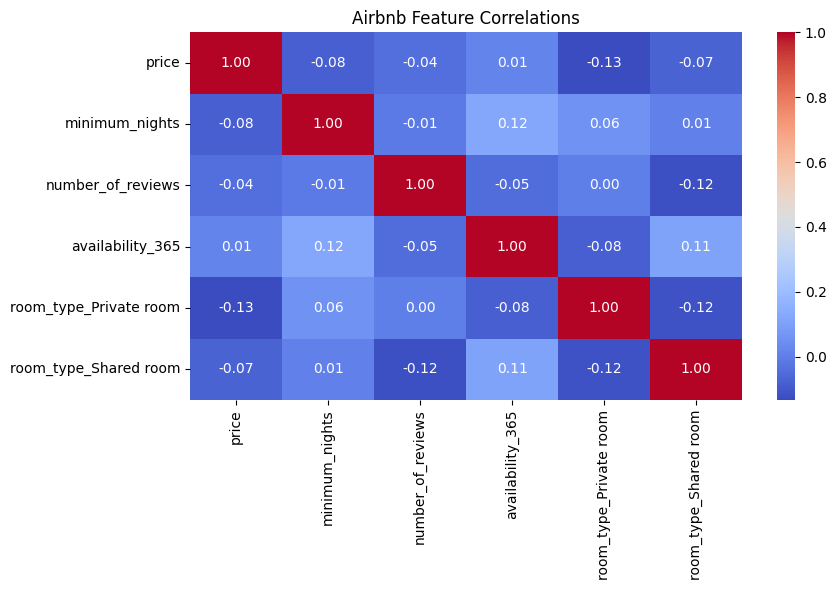

room_type_Private room   -0.133232
minimum_nights           -0.082573
room_type_Shared room    -0.073502
number_of_reviews        -0.043057
availability_365          0.013163
Name: price, dtype: float64


In [4]:
# Calculate correlations
correlation_matrix = df.corr(numeric_only=True)

# Display a heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Airbnb Feature Correlations')
plt.tight_layout()
plt.show()

# Show correlations with price, strongest first by absolute value
price_correlations = correlation_matrix['price'].drop('price')
print(price_correlations.sort_values(
    key=lambda values: values.abs(),
    ascending=False
))

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. Private rooms had the strongest negative correlation with price at −0.133, followed by minimum nights at −0.083. Availability had the only positive correlation at 0.013. All of these relationships were weak.

2. Room type and minimum nights may be useful predictors, but their weak correlations suggest they won’t explain much of the price variation on their own.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [5]:
# Target: the price we want to predict
y = df['price']

# Features: all remaining columns
X = df.drop(columns=['price'])

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['minimum_nights', 'number_of_reviews', 'availability_365', 'room_type_Private room', 'room_type_Shared room']
Target: price


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. I’m using minimum nights, number of reviews, availability, and the private-room and shared-room indicators to predict price. Entire homes are the reference room type.

2. This is a regression problem because we’re predicting a numerical price rather than a category.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 5)
Testing data: (30, 5)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [7]:
# Train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict prices for the test listings
y_pred = linear_model.predict(X_test)

# Preview actual and predicted prices
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

display(comparison.head())

,Actual Price,Predicted Price
73,232.79,118.543762
18,97.86,167.820274
118,297.70,117.247399
78,83.27,116.843261
76,207.03,48.904462


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [8]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
rmse = mse ** 0.5

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared: {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"Average test price: ${y_test.mean():.2f}")

Mean Squared Error (MSE): 15589.86
R-squared: -0.0841
Root Mean Squared Error (RMSE): $124.86
Average test price: $135.68


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. My R-squared is −0.0841, which means the model predicts worse than simply using the average test price for every listing. It does not explain price variation well.

2. The MSE is 15,589.86, and the RMSE is $124.86, which is large compared with the average price of $135.68. Adding features like location, bedrooms, and amenities could help improve predictions.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [9]:
# Create a table of features and coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': linear_model.coef_
})

# Sort by coefficient size while keeping positive/negative signs
coefficients['Absolute Coefficient'] = coefficients['Coefficient'].abs()
coefficients = coefficients.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

display(coefficients)

,Feature,Coefficient,Absolute Coefficient
4,room_type_Shared room,-61.285542,61.285542
3,room_type_Private room,-40.346700,40.346700
0,minimum_nights,-2.182980,2.182980
1,number_of_reviews,-0.895709,0.895709
2,availability_365,-0.067126,0.067126


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. None of the features had positive coefficients. Compared with entire homes, shared rooms had predicted prices about $61.29 lower, and private rooms about $40.35 lower, holding other features constant.

2. The negative coefficient for reviews surprised me because I thought more reviews might support higher prices. However, this result does not mean that getting more reviews causes prices to fall.

3. Room type may be useful when comparing listing prices. However, the model’s poor test performance means hosts should not rely on these estimates alone to set prices.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [10]:
# Select the top three features
top_features = coefficients.head(3)['Feature'].tolist()
print("Selected features:", top_features)

# Keep the same training and test listings
X_train_refined = X_train[top_features]
X_test_refined = X_test[top_features]

# Train the refined model and predict prices
refined_model = LinearRegression()
refined_model.fit(X_train_refined, y_train)

y_pred_refined = refined_model.predict(X_test_refined)

# Evaluate the refined model
mse_refined = mean_squared_error(y_test, y_pred_refined)
r2_refined = r2_score(y_test, y_pred_refined)

# Compare both models
results = pd.DataFrame({
    'Model': ['Baseline', 'Refined'],
    'MSE': [mse, mse_refined],
    'R-squared': [r2, r2_refined]
})

display(results.round(4))

Selected features: ['room_type_Shared room', 'room_type_Private room', 'minimum_nights']


,Model,MSE,R-squared
0,Baseline,15589.8630,-0.0841
1,Refined,15104.2277,-0.0503


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept the shared-room indicator, private-room indicator, and minimum nights because they had the largest absolute coefficients, following the assignment’s selection method.

2. Performance improved slightly. MSE decreased from 15,589.86 to 15,104.23, and R-squared improved from −0.0841 to −0.0503. Removing the other features may have reduced noise, but the model still performed poorly.

3. I would recommend the refined model as a starting point because it is simpler and performed slightly better. However, neither model is accurate enough to guide pricing decisions on its own.

4. My learning outcome is to gain practical experience I can use later in life. This assignment helped me practice building models, comparing results, and recognizing when predictions aren’t reliable enough to support a business decision.

## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. My model helped explore whether room type, minimum stays, reviews, and availability could predict Airbnb prices. These features alone did not predict prices well.

2. I would recommend that hosts compare similar nearby listings and consider location, property size, and amenities when setting prices. I would not recommend relying on this model alone.

3. Next, I would add more listings and features like bedrooms, location, and amenities. I would also compare other models to see whether they predict prices more accurately.

4. This assignment gave me experience turning data into a model and explaining the results in plain language. These skills could help me evaluate information and make better decisions in future jobs.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [11]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_11_regression.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
